# Tensorboard

## Import Required Modules from Tensorboard

In [1]:
from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter("runs/mnist")

In [2]:
import torch

print(torch.cuda.is_available())

True


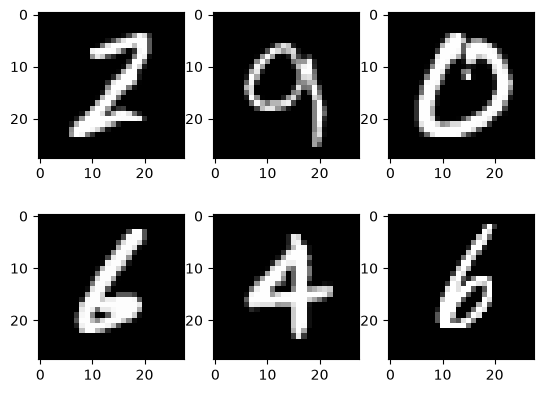

Epoch 1, Step 100/600: loss = 0.3021278381347656 
Epoch 1, Step 200/600: loss = 0.3095817565917969 
Epoch 1, Step 300/600: loss = 0.2645943760871887 
Epoch 1, Step 400/600: loss = 0.3972272574901581 
Epoch 1, Step 500/600: loss = 0.2548171579837799 
Epoch 1, Step 600/600: loss = 0.3845307230949402 
Epoch 2, Step 100/600: loss = 0.11290068924427032 
Epoch 2, Step 200/600: loss = 0.1507214903831482 
Epoch 2, Step 300/600: loss = 0.14698857069015503 
Epoch 2, Step 400/600: loss = 0.12300917506217957 
Epoch 2, Step 500/600: loss = 0.19588826596736908 
Epoch 2, Step 600/600: loss = 0.18633487820625305 
Epoch 3, Step 100/600: loss = 0.07891592383384705 
Epoch 3, Step 200/600: loss = 0.18529537320137024 
Epoch 3, Step 300/600: loss = 0.12190742790699005 
Epoch 3, Step 400/600: loss = 0.1377386897802353 
Epoch 3, Step 500/600: loss = 0.07322148233652115 
Epoch 3, Step 600/600: loss = 0.1286294311285019 
Epoch 4, Step 100/600: loss = 0.05701296776533127 
Epoch 4, Step 200/600: loss = 0.18223014

In [8]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import sys
import torch.nn.functional as F


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


input_size = 784 # 28x28 images
hidden_size = 100
num_classes = 10
num_epochs = 10
batch_size = 100
learning_rate = 0.001


train_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transforms.ToTensor(), download=True)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, transform=transforms.ToTensor())

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

examples = iter(train_loader)
samples, labels = next(examples)
samples.shape, labels.shape


for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(samples[i][0], cmap='gray')
plt.show()

img_grid = torchvision.utils.make_grid(samples)
writer.add_image('mnist_images', img_grid)
writer.close()


class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(NeuralNet, self).__init__()
        self.l1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.l2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out = self.l1(x)
        out = self.relu(out)
        out = self.l2(out)
        return out

model = NeuralNet(input_size, hidden_size, num_classes).to(device)


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

writer.add_graph(model, samples.reshape(-1, 28*28).to(device))
writer.close()


n_total_steps = len(train_loader)

running_loss = 0.0
running_corrects = 0.0
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        # reshape from (100, 1, 28, 28) to (100, 784)
        images = images.reshape(-1, 28*28).to(device)
        labels = labels.to(device)

        # forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        running_corrects += (predicted == labels).sum().item()
        
        if (i+1) % 100 == 0:
            print(f"Epoch {epoch+1}, Step {i+1}/{n_total_steps}: loss = {loss.item()} ")
            writer.add_scalar('training loss', running_loss / 100, epoch * n_total_steps + i)
            writer.add_scalar('accuracy', running_corrects / 100 / predicted.size(0), epoch * n_total_steps +i)
            writer.close()
            running_loss = 0.0
            running_corrects = 0.0


class_labels = []
class_preds = []
with torch.no_grad():
    n_correct = 0
    n_samples = 0
    for images, labels in test_loader:
        images = images.reshape(-1, 28*28).to(device)
        labels = labels.to(device)
        outputs = model(images)

        _, predictions = torch.max(outputs, 1)
        n_samples += labels.shape[0]
        n_correct += (predictions == labels).sum().item()

        class_probs_batch = [F.softmax(output, dim=0) for output in outputs]
        class_preds.append(class_probs_batch)
        class_labels.append(labels)

    class_preds = torch.cat([torch.stack(batch) for batch in class_preds]) # (10000, 10)
    class_labels = torch.cat(class_labels) # (10000, 1)
    
    acc = 100.0 * n_correct / n_samples
    print(f"Accuray: {acc}")

    classes = range(10)
    for i in classes:
        labels_i = class_labels == i
        preds_i = class_preds[:, i]
        writer.add_pr_curve(str(i), labels_i, preds_i, global_step=0)
        writer.close()